# 02_train_baseline.ipynb
Notebook này sử dụng FLAML AutoML để huấn luyện mô hình baseline trên tập dữ liệu đã làm sạch. Đánh giá độ chính xác và trực quan hóa độ quan trọng của toàn bộ 79 đặc trưng trên một ảnh duy nhất.

## 1. Import libraries và đọc dữ liệu
Đọc dữ liệu đã làm sạch.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle
import warnings
from sklearn.model_selection import train_test_split
from flaml import AutoML
import shap

warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
df = pd.read_csv("../data/processed/train_clean.csv", keep_default_na=False)
df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,4.189655,9.042040,Pave,NA,Reg,Lvl,AllPub,Inside,...,0.0,NA,NA,NA,0.0,2,2008,WD,Normal,12.247699
1,20,RL,4.394449,9.169623,Pave,NA,Reg,Lvl,AllPub,FR2,...,0.0,NA,NA,NA,0.0,5,2007,WD,Normal,12.109016
2,60,RL,4.234107,9.328212,Pave,NA,IR1,Lvl,AllPub,Inside,...,0.0,NA,NA,NA,0.0,9,2008,WD,Normal,12.317171
3,70,RL,4.110874,9.164401,Pave,NA,IR1,Lvl,AllPub,Corner,...,0.0,NA,NA,NA,0.0,2,2006,WD,Abnorml,11.849405
4,60,RL,4.442651,9.565284,Pave,NA,IR1,Lvl,AllPub,FR2,...,0.0,NA,NA,NA,0.0,12,2008,WD,Normal,12.429220


## 2. Chia tập Train / Validation
Chia dữ liệu theo tỷ lệ 80% train / 20% validation với random_state=42 để cố định tập phân chia.

In [3]:
X = df.drop(columns=["SalePrice"])
y = df["SalePrice"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

## 3. Huấn luyện mô hình bằng FLAML AutoML
Dùng automl để tìm mô hình và hyperparameter một cách tối giản.

In [4]:
automl = AutoML()

automl.fit(
    X_train=X_train,
    y_train=y_train,
    time_budget=120,
    metric="rmse",
    task="regression",
    seed=42,
    verbose=3
)

[flaml.automl.logger: 10-14 20:56:13] {2470} INFO - task = regression
[flaml.automl.logger: 10-14 20:56:13] {2481} INFO - Evaluation method: cv
[flaml.automl.logger: 10-14 20:56:13] {2584} INFO - Minimizing error metric: rmse
[flaml.automl.logger: 10-14 20:56:13] {2701} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd']
[flaml.automl.logger: 10-14 20:56:13] {3006} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 10-14 20:56:13] {3141} INFO - Estimated sufficient time budget=2760s. Estimated necessary time budget=20s.
[flaml.automl.logger: 10-14 20:56:13] {3192} INFO -  at 0.4s,	estimator lgbm's best error=3.1491e-01,	best estimator lgbm's best error=3.1491e-01
[flaml.automl.logger: 10-14 20:56:13] {3006} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 10-14 20:56:13] {3192} INFO -  at 0.7s,	estimator lgbm's best error=3.1491e-01,	best estimator lgbm's best error=3.1491e-01
[flaml.automl.logger: 10-14 2

## 4. Đánh giá độ chính xác
In tên thuật toán tốt nhất được lựa chọn và tính sai số RMSE trên tập validation.

In [5]:
print("Thuật toán tốt nhất:", automl.best_estimator)

val_pred = automl.predict(X_val)
val_rmse = np.sqrt(np.mean((y_val - val_pred) ** 2))
print(f"Validation RMSE: {val_rmse:.5f}")

Thuật toán tốt nhất: lgbm
Validation RMSE: 0.13560


## 5. Trực quan hóa bằng SHAP
Dùng thư viện SHAP để đánh giá độ quan trọng của từng cột.

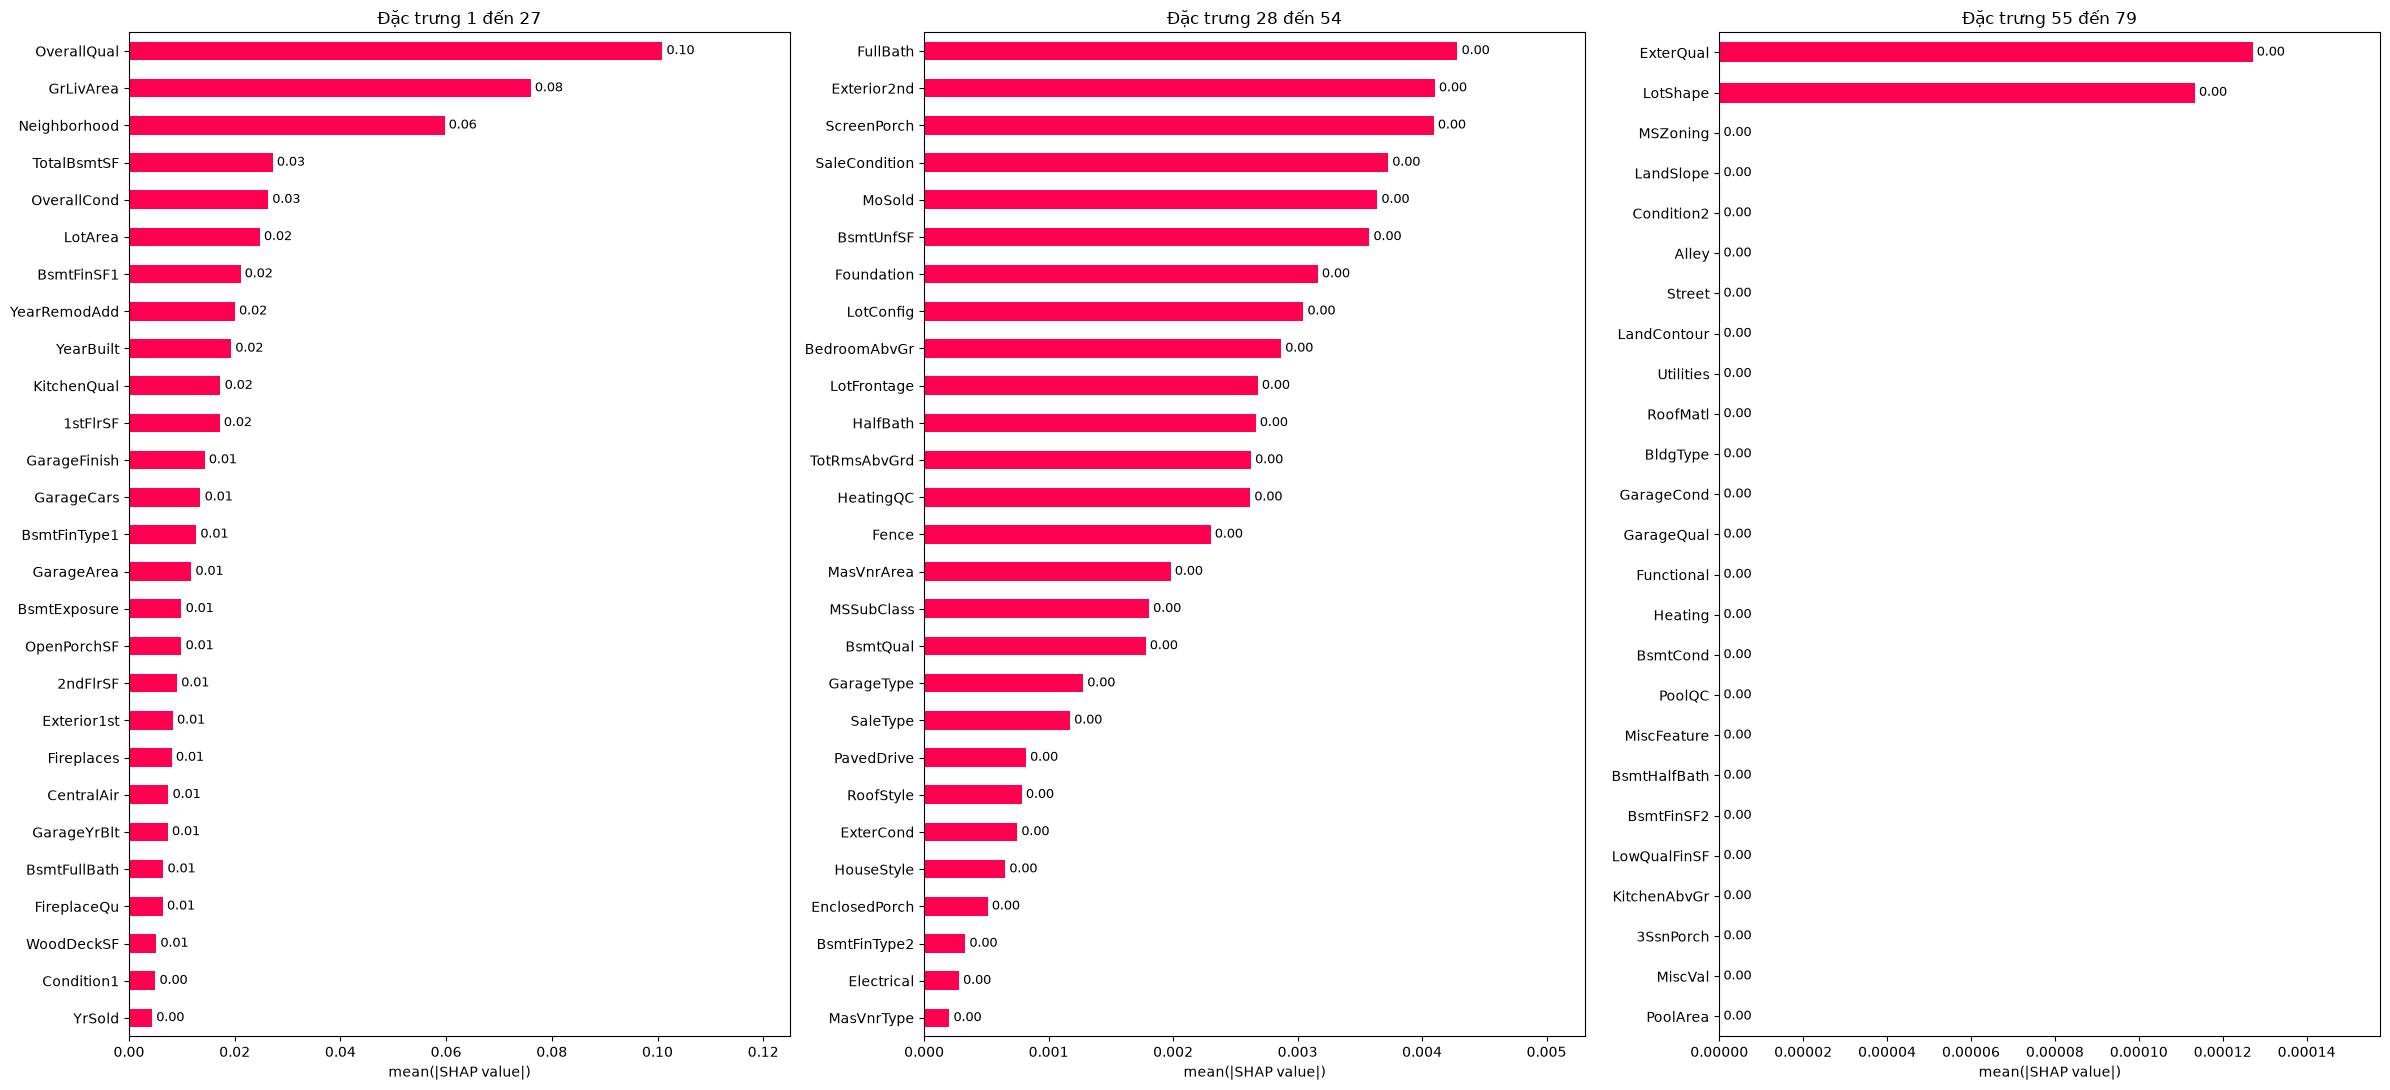

In [6]:
X_val_transformed = automl.model.preprocess(automl.preprocess(X_val))

explainer = shap.TreeExplainer(automl.model.estimator)
shap_values = explainer(X_val_transformed)

mean_shap = np.abs(shap_values.values).mean(axis=0)
feature_names = X_val_transformed.columns if hasattr(X_val_transformed, "columns") else shap_values.feature_names
shap_df = pd.Series(mean_shap, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(24, 11))
chunk_size = int(np.ceil(len(shap_df) / 3))

for idx, ax in enumerate(axes):
    start = idx * chunk_size
    end = min(start + chunk_size, len(shap_df))
    chunk = shap_df.iloc[start:end].iloc[::-1]
    chunk.plot(kind="barh", ax=ax, color="#ff0051")
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=3, fontsize=9)
    ax.set_xlim(right=ax.get_xlim()[1] * 1.18)
    ax.set_title(f"Đặc trưng {start + 1} đến {end}")
    ax.set_xlabel("mean(|SHAP value|)")

plt.tight_layout()
plt.show()